# 08c · Held-out gate experiment (Decision D22 / D23)

Gates: `gate_IF`, `gate_LOF`, `gate_ALL` (= IF and LOF and kNN, all must pass).
Detectors used to **evaluate** every counterfactual: IF, LOF, kNN (the gate pool) and **GMM, OCSVM (held-out: never used inside any gate)**.

**Decision rule (docs/decisions.md D22):**
- `gate_ALL` has verdict `transfer` on at least one held-out detector and single-detector gates do not -> multi-detector gate generalises (partially).
- `gate_ALL` has verdict `none` on both held-out detectors -> Goodhart effect persists with multi-detector gates.
- Anything else -> inconclusive.

In [1]:
import numpy as np
import pandas as pd

from conformal_trees.evaluation.paper_artifacts import (
    add_roles_and_verdicts,
    fig_flags_vs_reference,
    fig_paired_effects,
    flag_columns,
    load_benchmark,
    load_benchmark_ref,
    paired_effects,
    summary_strings,
    summary_tables,
)
from conformal_trees.utils import resolve_path

pd.set_option("display.max_columns", 50)
CSV = resolve_path("results/raw/gate_benchmark.csv")
df = load_benchmark(CSV)
ref = load_benchmark_ref(CSV.with_name(CSV.stem + "_reference.csv"))
TARGET = 0.6
GATES = [g for g in df.gate.unique() if g != "none"]

print(f"dataset: {df.dataset.unique().tolist()}, seeds: {sorted(df.seed.unique())}, individuals/seed: {df.groupby('seed').i.nunique().iloc[0]}")
print("gates:", GATES, "| detectors:", [c[5:] for c in flag_columns(df)])

dataset: ['adult'], seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)], individuals/seed: 200
gates: ['gate_IF', 'gate_LOF', 'gate_ALL'] | detectors: ['IF', 'LOF', 'kNN', 'GMM', 'OCSVM']


## 1. Per method (target 0.6): mean ± sd across seeds

In [2]:
mean, sd = summary_tables(df)
display(summary_strings(mean, sd).xs(TARGET, level="target"))
display(ref.groupby("group")[flag_columns(ref)].agg(["mean", "std"]).round(3))

success           cost      n_changed        flag_IF  \
variant gate                                                                   
main    gate_ALL  0.542 ± 0.029  2.722 ± 0.148  2.360 ± 0.043  0.004 ± 0.005   
        gate_IF   0.565 ± 0.036  2.801 ± 0.190  2.365 ± 0.021  0.019 ± 0.014   
        gate_LOF  0.594 ± 0.042  2.866 ± 0.182  2.407 ± 0.043  0.087 ± 0.021   
        none      0.597 ± 0.044  2.861 ± 0.210  2.381 ± 0.040  0.093 ± 0.022   

                       flag_LOF       flag_kNN       flag_GMM     flag_OCSVM  \
variant gate                                                                   
main    gate_ALL  0.018 ± 0.011  0.020 ± 0.017  0.020 ± 0.008  0.066 ± 0.018   
        gate_IF   0.088 ± 0.025  0.077 ± 0.024  0.035 ± 0.013  0.103 ± 0.029   
        gate_LOF  0.023 ± 0.014  0.120 ± 0.017  0.062 ± 0.029  0.147 ± 0.026   
        none      0.085 ± 0.016  0.135 ± 0.022  0.067 ± 0.031  0.161 ± 0.032   

                         robust  
variant gate                     
main    gate_ALL  0.915 ± 0.033  
        gate_IF   0.907 ± 0.026  
        gate_LOF  0.902 ± 0.031  
        none      0.901 ± 0.029

flag_IF        flag_LOF        flag_kNN        flag_GMM  \
                         mean    std     mean    std     mean    std     mean   
group                                                                           
original_unfavourable   0.054  0.014    0.070  0.021    0.056  0.016    0.048   
real_favourable         0.071  0.007    0.044  0.004    0.064  0.009    0.079   

                             flag_OCSVM         
                         std       mean    std  
group                                           
original_unfavourable  0.018      0.042  0.008  
real_favourable        0.007      0.074  0.010

## 2. Paired effect of each gate on each detector (Pre-registered verdict)

In [3]:
effects = add_roles_and_verdicts(paired_effects(df, GATES, [TARGET], flag_columns(df)), require_holm=True)
cols = ["gate", "metric", "role", "diff", "ci_low", "ci_high", "n_pairs", "only_gate", "only_none", "p", "p_holm", "seeds_drop_2pts", "n_seeds", "verdict"]
display(effects[cols].round(4))

print("=== HELD-OUT VERDICT SUMMARY (Decision D22) ===")
display(effects[effects.role == "held-out"][["gate", "metric", "diff", "ci_low", "ci_high", "p_holm", "verdict"]].round(4))

,gate,metric,role,diff,ci_low,ci_high,n_pairs,only_gate,only_none,p,p_holm,seeds_drop_2pts,n_seeds,verdict
0,gate_IF,flag_IF,own,-0.0230,-0.0354,-0.0106,565,0,13,0.0002,0.0027,2,5,
1,gate_IF,flag_LOF,pool (not in gate),0.0035,-0.0035,0.0106,565,3,1,0.6250,1.0000,0,5,none
2,gate_IF,flag_kNN,pool (not in gate),-0.0142,-0.0265,-0.0035,565,1,9,0.0215,0.1934,1,5,inconclusive
3,gate_IF,flag_GMM,held-out,-0.0035,-0.0106,0.0035,565,1,3,0.6250,1.0000,0,5,none
4,gate_IF,flag_OCSVM,held-out,-0.0142,-0.0265,-0.0035,565,1,9,0.0215,0.1934,2,5,inconclusive
5,gate_LOF,flag_IF,pool (not in gate),-0.0017,-0.0084,0.0051,593,2,3,1.0000,1.0000,0,5,none
6,gate_LOF,flag_LOF,own,-0.0573,-0.0776,-0.0388,593,1,35,0.0000,0.0000,5,5,
7,gate_LOF,flag_kNN,pool (not in gate),-0.0101,-0.0202,-0.0017,593,1,7,0.0703,0.4922,0,5,inconclusive
8,gate_LOF,flag_GMM,held-out,-0.0051,-0.0118,0.0000,593,0,3,0.2500,1.0000,0,5,none
9,gate_LOF,flag_OCSVM,held-out,-0.0101,-0.0202,-0.0017,593,1,7,0.0703,0.4922,0,5,inconclusive


=== HELD-OUT VERDICT SUMMARY (Decision D22) ===


,gate,metric,diff,ci_low,ci_high,p_holm,verdict
3,gate_IF,flag_GMM,-0.0035,-0.0106,0.0035,1.0000,none
4,gate_IF,flag_OCSVM,-0.0142,-0.0265,-0.0035,0.1934,inconclusive
8,gate_LOF,flag_GMM,-0.0051,-0.0118,0.0000,1.0000,none
9,gate_LOF,flag_OCSVM,-0.0101,-0.0202,-0.0017,0.4922,inconclusive
13,gate_ALL,flag_GMM,-0.0092,-0.0185,0.0000,0.6250,none
14,gate_ALL,flag_OCSVM,-0.0296,-0.0444,-0.0166,0.0004,transfer


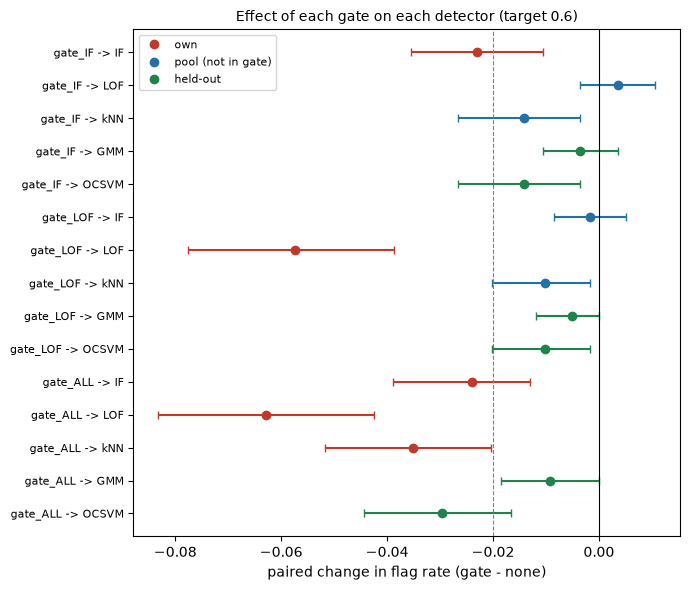

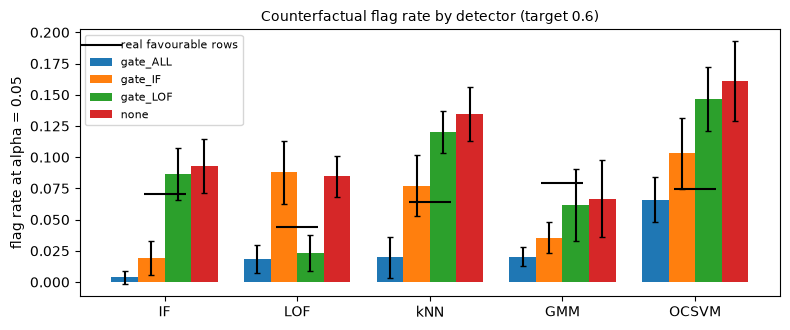

In [4]:
fig_paired_effects(effects, TARGET)
fig_flags_vs_reference(df, ref, TARGET);

## 3. What the gates cost

In [5]:
cost = paired_effects(df, GATES, [TARGET], ["cost", "n_changed", "robust"])
display(cost[["gate", "metric", "diff", "ci_low", "ci_high", "n_pairs"]].round(4))
display(mean.xs(TARGET, level="target")[["success"]].round(3))

,gate,metric,diff,ci_low,ci_high,n_pairs
0,gate_IF,cost,0.0248,0.0116,0.0415,565
1,gate_IF,n_changed,0.0230,0.0088,0.0389,565
2,gate_IF,robust,0.0018,-0.0029,0.0071,565
3,gate_LOF,cost,0.0167,0.0041,0.0303,593
4,gate_LOF,n_changed,0.0304,0.0135,0.0506,593
5,gate_LOF,robust,0.0006,-0.0062,0.0062,593
6,gate_ALL,cost,0.0536,0.0338,0.0790,541
7,gate_ALL,n_changed,0.0573,0.0314,0.0850,541
8,gate_ALL,robust,0.0049,-0.0031,0.0136,541


success
variant gate             
main    gate_ALL    0.542
        gate_IF     0.565
        gate_LOF    0.594
        none        0.597